Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (183.95154504, -17.54193046)>
Closest star found within the JMDC is:
 -Star ids: HD106625 or GAM CRV
- Stellar diameter: 0.72


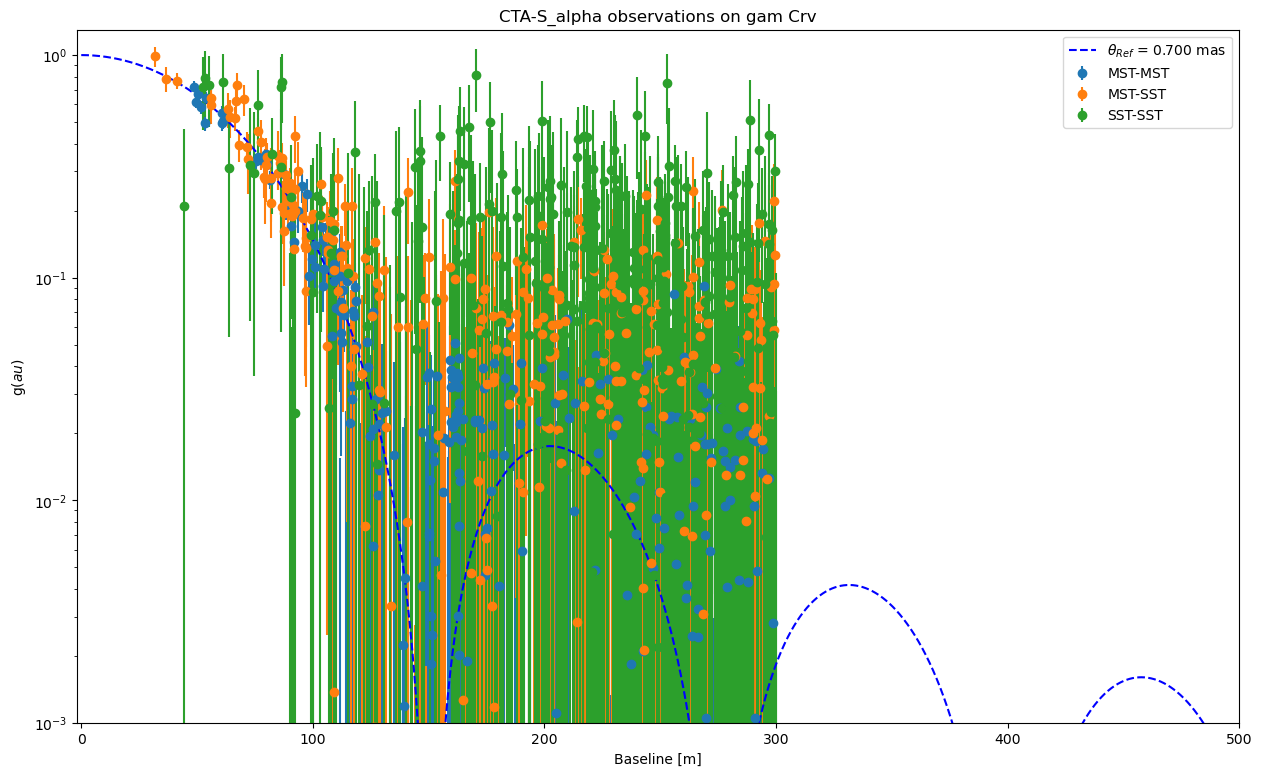

CPU times: user 11.2 s, sys: 2.51 s, total: 13.7 s
Wall time: 10.2 s


In [1]:
%%time

import astropy.units as u
import numpy as np
import os
import yaml
import scipy
import glob
import scipy.stats
import matplotlib.pyplot as plt
from spysii.sim_run import SimulateSiiRuns
from astropy.time import Time

sim_run = SimulateSiiRuns("gam Crv", observatory_name="CTA-S_alpha")

times = ['2021-03-12T00:00:00',
         '2021-03-12T00:45:00',
         '2021-03-12T01:30:00',
         '2021-03-12T03:00:00', 
         '2021-03-12T04:30:00', 
         '2021-03-12T06:00:00', 
         '2021-03-12T07:30:00']

time_array = Time(times, format='isot', scale='utc')

sim_run.stellar_diameter = 0.7 * u.mas

# # Create a rule for ignoring baselines:
baseline_threshold = 150*(1.4/sim_run.stellar_diameter.to("mas").value)

sim_run.simulate_observations(time_array, 
                              run_duration=34.3*u.min, # Total of 2h
                              ignore_larger_baselines=baseline_threshold, 
                              fast_simulation=True)

sim_run.plot_v2(set_log_yscale=True)


# sim_run.add_zbc_measurement(1., 0.01, "Combined")

# # sim_run.plot_v2(set_log_yscale=True)
# sim_run.fit_uniform_disc()
# sim_run.plot_uv()

# fit_results = sim_run.uniform_disc_fit
# fit_results['theta_e']/fit_results['theta']
# sim_run.f.get_axes()[0].set_xlim([0, 400])
# sim_run.f.legend().set_bbox_to_anchor = (1.3, 1.00)
# sim_run.f.legend().set_loc='bottom left'

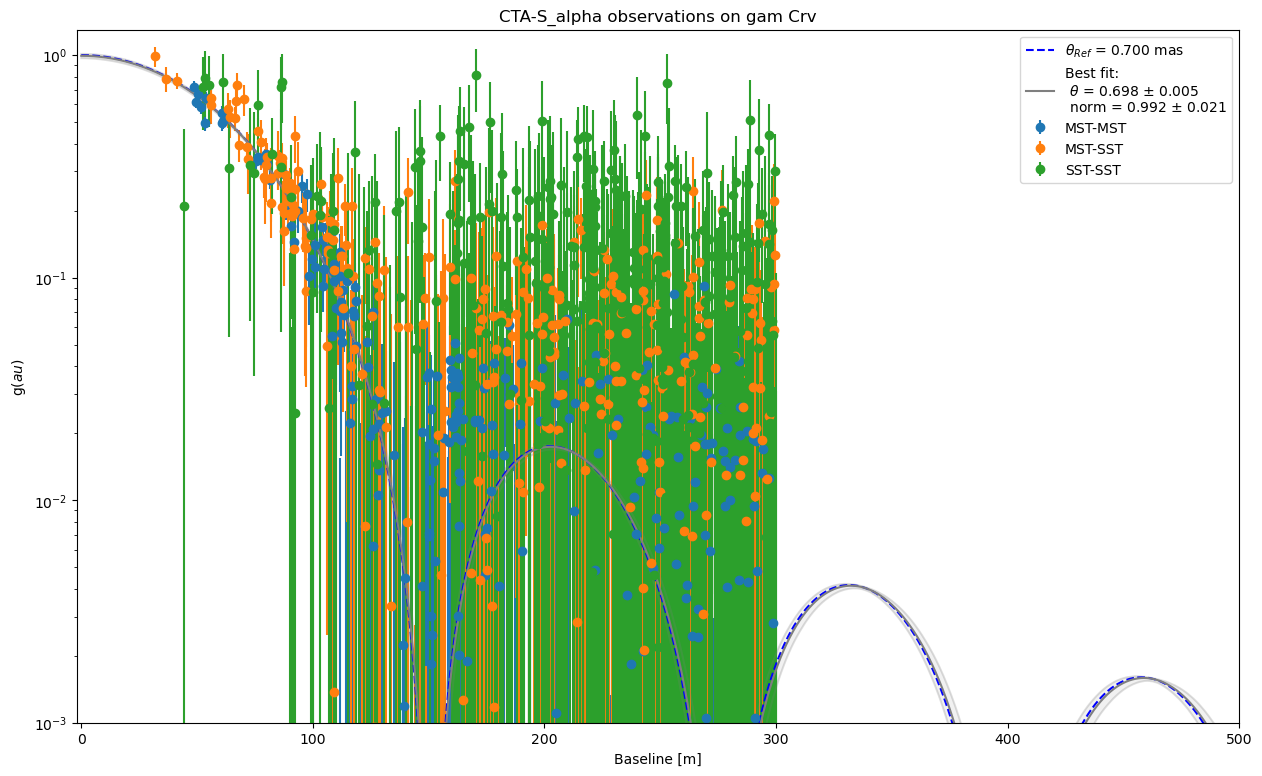

In [3]:
sim_run.fit_uniform_disc()
sim_run.plot_v2(set_log_yscale=True)

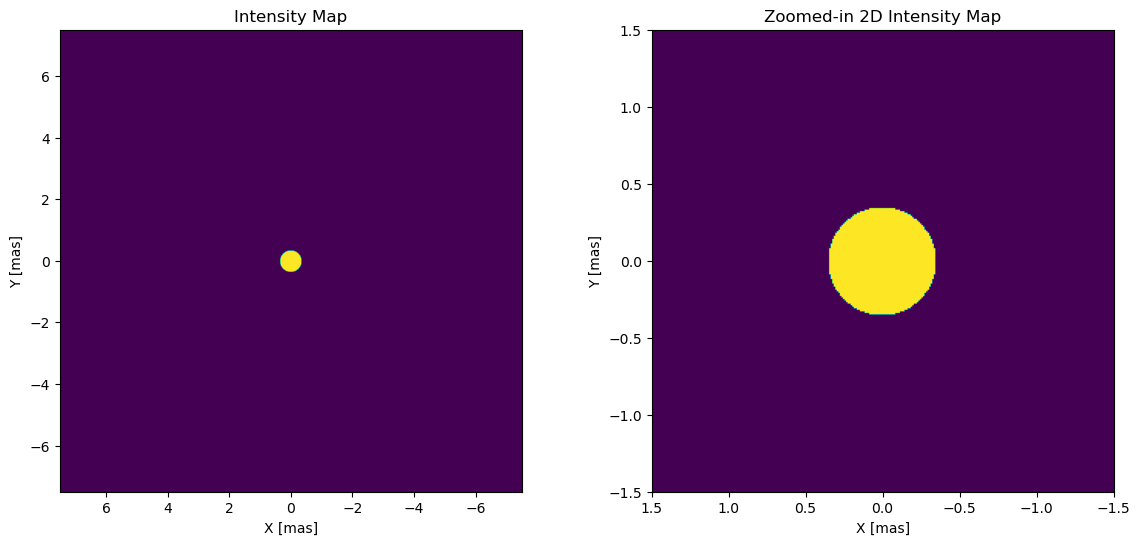

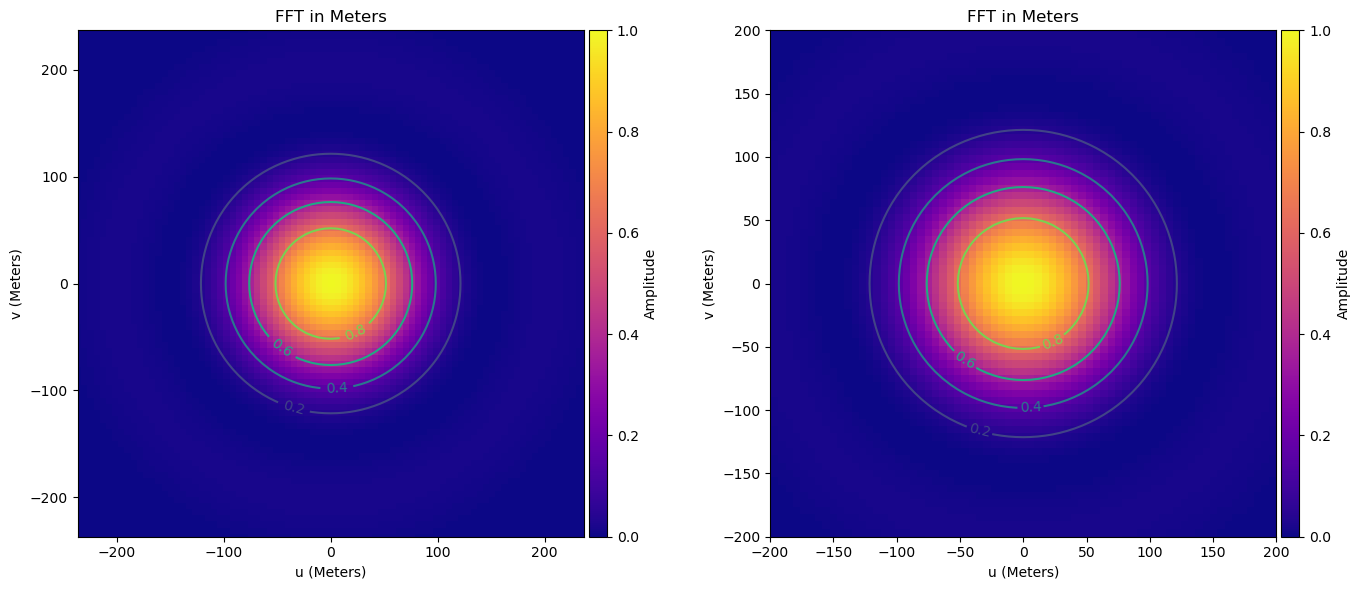

In [7]:
from spysii.sky_image import SkyImage
sky_image = SkyImage(1500, 0.01)
# Remember sky_image takes the radius, not the diameter:
sky_image.add_uniform_disc(0.70/2.)
sky_image.plot_image()
sky_image.plot_visibility()

Now we will use the generated V²(u,v) from sky_image to produce the simulation (assuming the location of gam Crv in the sky):

Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (183.95154504, -17.54193046)>
Closest star found within the JMDC is:
 -Star ids: HD106625 or GAM CRV
- Stellar diameter: 0.72


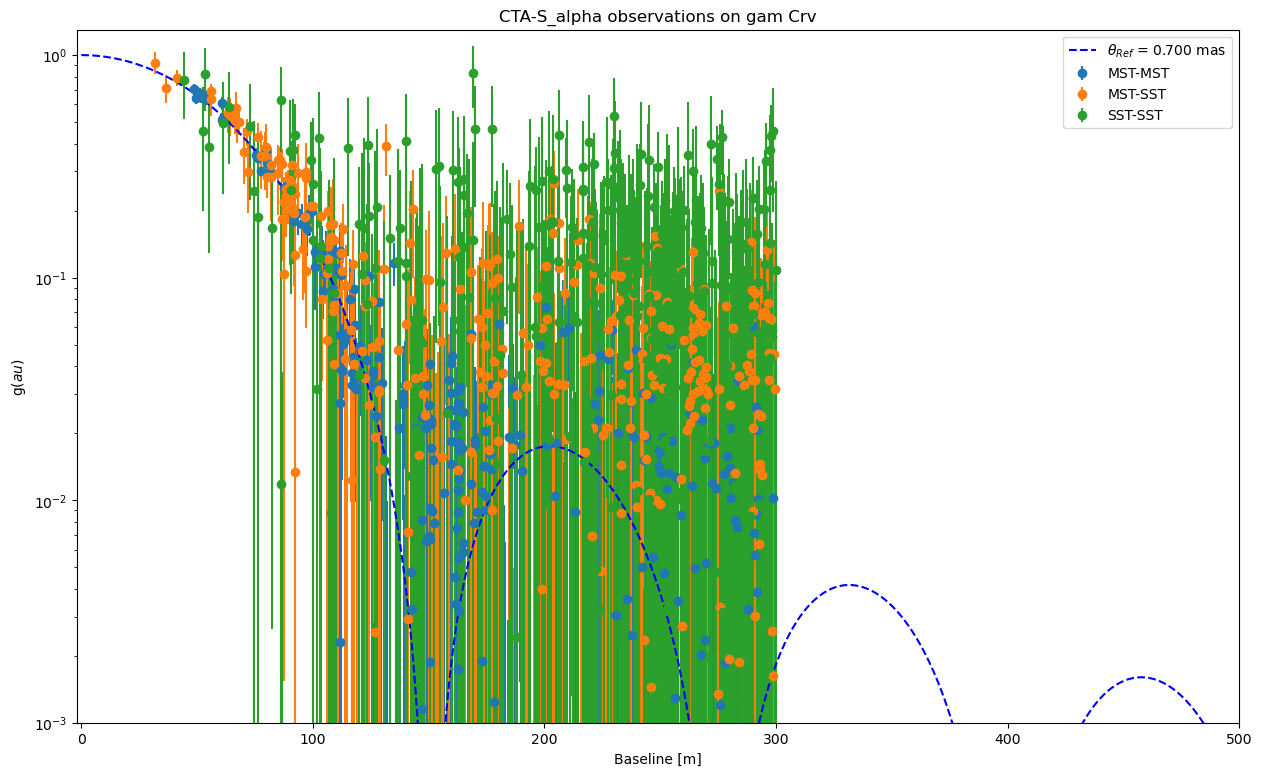

In [8]:
sim_run = SimulateSiiRuns("gam Crv", observatory_name="CTA-S_alpha", sky_image=sky_image)

times = ['2021-03-12T00:00:00',
         '2021-03-12T00:45:00',
         '2021-03-12T01:30:00',
         '2021-03-12T03:00:00', 
         '2021-03-12T04:30:00', 
         '2021-03-12T06:00:00', 
         '2021-03-12T07:30:00']

time_array = Time(times, format='isot', scale='utc')

sim_run.stellar_diameter = 0.7 * u.mas

# # Create a rule for ignoring baselines:
baseline_threshold = 150*(1.4/sim_run.stellar_diameter.to("mas").value)

sim_run.simulate_observations(time_array, 
                              run_duration=34.3*u.min, # Total of 2h
                              ignore_larger_baselines=baseline_threshold, 
                              fast_simulation=True)

sim_run.plot_v2(set_log_yscale=True)